In [44]:
import os
from typing import List, TypedDict
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import Chroma
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import END, StateGraph
import requests
from dotenv import load_dotenv
load_dotenv()
# Set your API key
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [45]:
# Initialize the LLM
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [46]:
def download_default_pdf(raw_url: str, save_path: str):
    """Downloads the default PDF if it doesn't already exist locally."""
    if not os.path.exists(save_path):
        print(f"Downloading textbook from GitHub... This might take a moment.")
        response = requests.get(raw_url)
        response.raise_for_status()
        
        with open(save_path, 'wb') as f:
            f.write(response.content)
        print("Download complete!")
    else:
        print("Default textbook already exists locally. Skipping download.")

def ingest_pdf(file_path: str):
    """Loads a PDF and splits it into chunks."""
    print(f"Loading and splitting: {file_path}")
    loader = PyPDFLoader(file_path)
    docs = loader.load()
    
    # Using a slightly larger chunk size for a textbook to capture full paragraphs
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)
    return text_splitter.split_documents(docs)

# 1. Define the raw GitHub URL and local filename
GITHUB_RAW_URL = "https://raw.githubusercontent.com/janishar/mit-deep-learning-book-pdf/master/complete-book-pdf/Ian%20Goodfellow%2C%20Yoshua%20Bengio%2C%20Aaron%20Courville%20-%20Deep%20Learning%20(2017%2C%20MIT).pdf"
DEFAULT_PDF_FILENAME = "goodfellow_deep_learning.pdf"

# 2. Download the book
download_default_pdf(GITHUB_RAW_URL, DEFAULT_PDF_FILENAME)

# 3. Initialize empty Chroma DB
vectorstore = Chroma(
    collection_name="dl-tutor-chroma",
    embedding_function=OpenAIEmbeddings(),
    persist_directory="./chroma_db"
)

# 4. Ingest and embed the book
print("Processing documents for the vector store...")
default_docs = ingest_pdf(DEFAULT_PDF_FILENAME)
vectorstore.add_documents(default_docs)
print(f"Successfully added {len(default_docs)} chunks to the knowledge base.")

# 5. Set up the retriever
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

Default textbook already exists locally. Skipping download.
Processing documents for the vector store...
Loading and splitting: goodfellow_deep_learning.pdf
Successfully added 3053 chunks to the knowledge base.


In [47]:
class GraphState(TypedDict):
    question: str
    generation: str
    documents: List[str]
    loop_step: int

In [48]:
def retrieve(state):
    print("---RETRIEVING DOCUMENTS---")
    question = state["question"]
    documents = retriever.invoke(question)
    return {"documents": documents, "question": question}

def grade_documents(state):
    print("---GRADING DOCUMENT RELEVANCE---")
    question = state["question"]
    documents = state["documents"]
    
    # Prompt for the LLM to act as a grader
    prompt = ChatPromptTemplate.from_template(
        "You are a grader assessing relevance of a retrieved document to a user question.\n"
        "Here is the retrieved document: \n\n {document} \n\n"
        "Here is the user question: {question}\n"
        "If the document contains keyword(s) or semantic meaning related to the user question, grade it as relevant.\n"
        "Give a binary score 'yes' or 'no' score to indicate whether the document is relevant to the question."
    )
    
    grader_chain = prompt | llm | StrOutputParser()
    
    filtered_docs = []
    for d in documents:
        score = grader_chain.invoke({"question": question, "document": d.page_content})
        if "yes" in score.lower():
            filtered_docs.append(d)
            
    return {"documents": filtered_docs, "question": question}

def generate(state):
    print("---GENERATING ANSWER---")
    question = state["question"]
    documents = state["documents"]
    
    context = "\n\n".join([d.page_content for d in documents])
    
    prompt = ChatPromptTemplate.from_template(
        "You are an expert deep learning tutor. Use the following pieces of retrieved context to answer the question.\n"
        "If you don't know the answer based on the context, just say that you don't know.\n"
        "Context: {context}\n"
        "Question: {question}\n"
        "Answer:"
    )
    
    rag_chain = prompt | llm | StrOutputParser()
    generation = rag_chain.invoke({"context": context, "question": question})
    
    return {"documents": documents, "question": question, "generation": generation}

def rewrite_query(state):
    print("---REWRITING QUERY (DL FOCUS)---")
    question = state["question"]
    # Get current loop step, default to 0 if not present
    loop_step = state.get("loop_step", 0) 
    
    prompt = ChatPromptTemplate.from_template(
        "You are an expert search assistant for a Deep Learning Concepts Tutor.\n"
        "Your task is to reformulate the user's initial question to optimize it for vector database retrieval.\n"
        "Crucially, you must ensure the rewritten question is explicitly framed within the context of Deep Learning, Neural Networks, or Machine Learning.\n"
        "Initial question: {question}\n"
        "Improved Deep Learning question:"
    )
    
    rewriter_chain = prompt | llm | StrOutputParser()
    rewritten_question = rewriter_chain.invoke({"question": question})
    
    return {"question": rewritten_question, "loop_step": loop_step + 1}

def check_hallucination(state):
    """
    Evaluates whether the generated answer is grounded in the retrieved documents.
    """
    print("---CHECKING FOR HALLUCINATIONS---")
    documents = state["documents"]
    generation = state["generation"]
    
    # Combine documents for context
    context = "\n\n".join([d.page_content for d in documents])
    
    prompt = ChatPromptTemplate.from_template(
        "You are a strict grader assessing whether an answer is grounded in / supported by a set of facts.\n"
        "Here are the facts (retrieved context): \n\n {context} \n\n"
        "Here is the generated answer: {generation}\n"
        "Give a binary score 'yes' or 'no' to indicate whether the answer is entirely grounded in the facts.\n"
        "If the answer contains ANY information not present in the facts, score it 'no'."
    )
    
    hallucination_chain = prompt | llm | StrOutputParser()
    score = hallucination_chain.invoke({"context": context, "generation": generation})
    
    if "yes" in score.lower():
        print("---DECISION: ANSWER IS GROUNDED (NO HALLUCINATION)---")
        return "grounded"
    else:
        print("---DECISION: HALLUCINATION DETECTED---")
        return "hallucinated"

In [49]:
def decide_to_generate(state):
    filtered_documents = state["documents"]
    loop_step = state.get("loop_step", 0)
    max_retries = 3 # Stop trying after 3 attempts
    
    if not filtered_documents:
        if loop_step >= max_retries:
            print(f"---DECISION: MAX RETRIES ({max_retries}) REACHED. FORCING GENERATION---")
            # We break the loop and send it to generate with empty documents
            return "generate"
        else:
            print(f"---DECISION: NO RELEVANT DOCUMENTS, REWRITING QUERY (Attempt {loop_step + 1}/{max_retries})---")
            return "rewrite_query"
    else:
        print("---DECISION: RELEVANT DOCUMENTS FOUND, GENERATING---")
        return "generate"

def decide_if_grounded(state):
    status = check_hallucination(state)
    loop_step = state.get("loop_step", 0)
    max_retries = 3
    
    if status == "grounded":
        return "useful"
    elif loop_step >= max_retries:
        print("---MAX RETRIES REACHED. RETURNING FALLBACK ANSWER---")
        return "max_retries"
    else:
        return "not_supported"

# Build the graph
workflow = StateGraph(GraphState)

# Add all nodes
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("rewrite_query", rewrite_query)

# Add standard edges
workflow.set_entry_point("retrieve")
workflow.add_edge("retrieve", "grade_documents")
workflow.add_edge("rewrite_query", "retrieve")

# Add the first conditional routing (Document Grading)
workflow.add_conditional_edges(
    "grade_documents",
    decide_to_generate,
    {
        "rewrite_query": "rewrite_query",
        "generate": "generate",
    },
)

# Add the new conditional routing (Hallucination Checking)
workflow.add_conditional_edges(
    "generate",
    decide_if_grounded,
    {
        "useful": END,               # Answer is good, end the graph
        "not_supported": "rewrite_query", # Hallucinated! Go get different context
        "max_retries": END           # Stop infinite loops
    }
)

# Compile
app = workflow.compile()

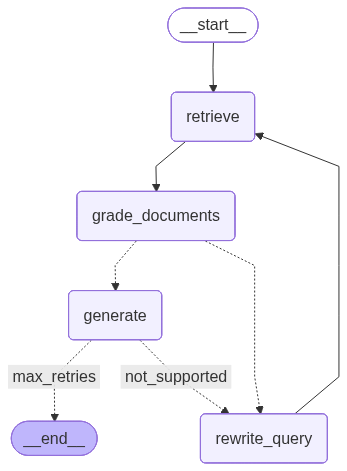

In [50]:
from IPython.display import Image, display

try:
    # Get the graph structure and render it as a PNG
    img_bytes = app.get_graph().draw_mermaid_png()
    
    # Display the image in the notebook output
    display(Image(img_bytes))
    
except Exception as e:
    print(f"Visualization failed. Ensure you have internet access for the Mermaid API. Error: {e}")

In [51]:
# Initial state
inputs = {"question": "Explain the role of activation functions.", "loop_step": 0}

print(f"User Question: {inputs['question']}\n")

# Stream the output
for output in app.stream(inputs):
    for key, value in output.items():
        pass # The print statements inside the nodes will show our progress

print("\n---FINAL ANSWER---")
print(value.get("generation"))

User Question: Explain the role of activation functions.

---RETRIEVING DOCUMENTS---
---GRADING DOCUMENT RELEVANCE---
---DECISION: RELEVANT DOCUMENTS FOUND, GENERATING---
---GENERATING ANSWER---
---CHECKING FOR HALLUCINATIONS---
---DECISION: HALLUCINATION DETECTED---
---REWRITING QUERY (DL FOCUS)---
---RETRIEVING DOCUMENTS---
---GRADING DOCUMENT RELEVANCE---
---DECISION: RELEVANT DOCUMENTS FOUND, GENERATING---
---GENERATING ANSWER---
---CHECKING FOR HALLUCINATIONS---
---DECISION: ANSWER IS GROUNDED (NO HALLUCINATION)---

---FINAL ANSWER---
Activation functions play a crucial role in neural networks within deep learning by introducing non-linearity into the model. This non-linearity allows the network to learn complex patterns and relationships in the data. Different activation functions, such as sigmoid and tanh, have specific properties that can affect the training process and the performance of the model. For instance, the tanh function is similar to the identity function near zero, 

In [52]:
inputs = {"question": "Explain the role of functions.", "loop_step": 0}

print(f"USER QUESTION: {inputs['question']}\n")
print("-" * 40)

for output in app.stream(inputs):
    for node_name, state_update in output.items():
        print(f"📍 CURRENT NODE: {node_name.upper()}")
        
        if "documents" in state_update:
            num_docs = len(state_update["documents"])
            print(f"   -> Documents in state: {num_docs}")
            
        if node_name == "rewrite_query":
            print(f"   -> New Query: {state_update['question']}")
            
        print("-" * 40)

print("\n✨ FINAL GENERATED ANSWER ✨")
print(state_update.get("generation"))

USER QUESTION: Explain the role of functions.

----------------------------------------
---RETRIEVING DOCUMENTS---
📍 CURRENT NODE: RETRIEVE
   -> Documents in state: 4
----------------------------------------
---GRADING DOCUMENT RELEVANCE---
---DECISION: NO RELEVANT DOCUMENTS, REWRITING QUERY (Attempt 1/3)---
📍 CURRENT NODE: GRADE_DOCUMENTS
   -> Documents in state: 0
----------------------------------------
---REWRITING QUERY (DL FOCUS)---
📍 CURRENT NODE: REWRITE_QUERY
   -> New Query: What is the role of activation functions in Deep Learning and Neural Networks?
----------------------------------------
---RETRIEVING DOCUMENTS---
📍 CURRENT NODE: RETRIEVE
   -> Documents in state: 4
----------------------------------------
---GRADING DOCUMENT RELEVANCE---
---DECISION: RELEVANT DOCUMENTS FOUND, GENERATING---
📍 CURRENT NODE: GRADE_DOCUMENTS
   -> Documents in state: 1
----------------------------------------
---GENERATING ANSWER---
---CHECKING FOR HALLUCINATIONS---
---DECISION: ANSWER IS